# Face Liveness Detection

Hệ thống nhận diện qua camera:

| Nhận diện | Số đo | Công cụ | Ngưỡng |
|---|---|---|---|
| **REAL / FAKE** | `p_real` (0…1) | **MiniFASNet** (MiniVision) | tính ở mục 4 (ROC trên tập train) |
| Mắt mở / nhắm | `EAR` (Eye Aspect Ratio: mở ≈ 0.3, nhắm ≈ 0) | MediaPipe, 6 điểm mốc mỗi mắt | tính ở mục 4 |
| Chớp mắt | số lần CLOSED → OPEN | EAR | dùng chung ngưỡng mắt |
| Xoay trái / phải | `yaw` (độ) | MediaPipe, **rotation matrix** | tính ở mục 4 |
| Ngẩng / cúi | `pitch` (độ) | MediaPipe, **rotation matrix** | tính ở mục 4 |

* Các ngưỡng **không gõ tay**: mục 4 tính từ dataset **NUAA** rồi lưu vào `results/thresholds.json`. Camera (mục 5) đọc đúng file này.
* Mục 6 (**vẽ bảng**) nằm cuối cùng: biểu đồ ngưỡng, ROC, confusion matrix, bảng ngưỡng.

In [1]:
import os, sys, json, math, time, zipfile, platform
from pathlib import Path
from collections import deque
import numpy as np, pandas as pd, cv2, torch, requests, mediapipe as mp, matplotlib.pyplot as plt
from mediapipe.tasks.python import vision as V, BaseOptions
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from tqdm.auto import tqdm

MODELS, DATA, RESULTS = Path("models"), Path("data"), Path("results")
for d in (MODELS, DATA, RESULTS): d.mkdir(exist_ok=True)

# Tải model nếu chưa có: MiniFASNet (MiniVision) + Face Landmarker (MediaPipe)
MV = "https://raw.githubusercontent.com/minivision-ai/Silent-Face-Anti-Spoofing/b6d5f04ad78778917853b25c778acef6d5626d15/"
for url in [MV + "src/model_lib/MiniFASNet.py",
            MV + "resources/anti_spoof_models/2.7_80x80_MiniFASNetV2.pth",
            MV + "resources/anti_spoof_models/4_0_0_80x80_MiniFASNetV1SE.pth",
            "https://storage.googleapis.com/mediapipe-models/face_landmarker/face_landmarker/float16/1/face_landmarker.task"]:
    file = MODELS / url.split("/")[-1]
    if not file.exists():
        r = requests.get(url, timeout=60); r.raise_for_status(); file.write_bytes(r.content)

## 1. MiniFASNet: điểm người thật `p_real`
Cắt vùng quanh mặt (rộng ×2.7 và ×4.0), thu về 80×80, cho qua 2 mạng MiniFASNet. Lấy trung bình xác suất lớp "người thật".

In [2]:
sys.path.insert(0, str(MODELS))
from MiniFASNet import MiniFASNetV2, MiniFASNetV1SE

def load_net(file, Net):
    net = Net(conv6_kernel=(5, 5), num_classes=3)
    w = torch.load(MODELS / file, map_location="cpu")
    w = {k.replace("module.", "").replace("se_fc", "se_module.fc").replace("se_bn", "se_module.bn"): v for k, v in w.items()}
    net.load_state_dict(w)                         # (sửa tên khóa trong file .pth cho khớp code)
    return net.eval()

NETS = [(load_net("2.7_80x80_MiniFASNetV2.pth", MiniFASNetV2), 2.7),
        (load_net("4_0_0_80x80_MiniFASNetV1SE.pth", MiniFASNetV1SE), 4.0)]

def crop_face(img, box, scale):
    """Cắt vùng quanh mặt rộng gấp `scale` lần hộp mặt, thu về 80x80."""
    x, y, w, h = box
    H, W = img.shape[:2]
    scale = min(scale, (H - 1) / h, (W - 1) / w)   # không vượt ra ngoài ảnh
    cx, cy = x + w / 2, y + h / 2                  # tâm mặt
    x1, x2 = int(max(0, cx - scale * w / 2)), int(min(W - 1, cx + scale * w / 2))
    y1, y2 = int(max(0, cy - scale * h / 2)), int(min(H - 1, cy + scale * h / 2))
    return cv2.resize(img[y1:y2 + 1, x1:x2 + 1], (80, 80))

@torch.no_grad()
def p_real(img, box):
    """Xác suất là người thật (0..1) = trung bình 2 mạng."""
    probs = []
    for net, scale in NETS:
        x = torch.tensor(crop_face(img, box, scale), dtype=torch.float32).permute(2, 0, 1)[None]
        probs.append(torch.softmax(net(x), dim=1)[0, 1].item())      # lớp 1 = người thật
    return sum(probs) / 2

## 2. MediaPipe: mắt và góc đầu (rotation matrix)
MediaPipe trả về **ma trận biến đổi** của khuôn mặt. Phần xoay là ma trận $R$ (3×3). Mỗi phép xoay quanh một trục là một ma trận:

$$
R_x(\theta)=\begin{bmatrix}1&0&0\\0&\cos\theta&-\sin\theta\\0&\sin\theta&\cos\theta\end{bmatrix}\ \text{(ngẩng/cúi: pitch)}\qquad
R_y(\psi)=\begin{bmatrix}\cos\psi&0&\sin\psi\\0&1&0\\-\sin\psi&0&\cos\psi\end{bmatrix}\ \text{(xoay trái/phải: yaw)}
$$
$$
R_z(\varphi)=\begin{bmatrix}\cos\varphi&-\sin\varphi&0\\\sin\varphi&\cos\varphi&0\\0&0&1\end{bmatrix}\ \text{(nghiêng: roll, không dùng)}
$$

Tư thế đầu là $R = R_y(\psi)\,R_x(\theta)\,R_z(\varphi)$. Nhân ra, các phần tử cần dùng là:

$$
R=\begin{bmatrix}R_{00}&R_{01}&R_{02}\\R_{10}&R_{11}&R_{12}\\R_{20}&R_{21}&R_{22}\end{bmatrix},\qquad
R_{02}=\sin\psi\cos\theta,\quad R_{22}=\cos\psi\cos\theta,\quad R_{12}=-\sin\theta
$$

Suy ra:

$$\boxed{\ \text{yaw}=\psi=\operatorname{atan2}(R_{02},\,R_{22})\ }\qquad \boxed{\ \text{pitch}=\theta=\arcsin(-R_{12})\ }$$

* `yaw > 0`: mặt quay về **bên phải màn hình**; `pitch > 0`: **cúi** xuống.
* Cell dưới có một phép **kiểm tra**: tạo $R$ từ góc biết trước, tách ngược lại phải ra đúng góc đó.
* **Mắt: EAR (Eye Aspect Ratio).** Mỗi mắt lấy 6 điểm mốc: $p_1, p_4$ là 2 khoé mắt, $p_2, p_3$ trên mí trên, $p_6, p_5$ trên mí dưới.

$$\text{EAR}=\frac{\lVert p_2-p_6\rVert+\lVert p_3-p_5\rVert}{2\,\lVert p_1-p_4\rVert}$$

  Tử số là chiều cao mắt, mẫu số là chiều rộng mắt. Mắt mở thì EAR ≈ 0.3, nhắm thì EAR gần 0. Lấy trung bình 2 mắt.
* `state` đổi số đo thành chữ theo ngưỡng. Camera được lật gương, nên trái/phải trên màn hình cũng là trái/phải của người dùng.

In [3]:
def landmarker(video=False):
    """Bộ dò mặt MediaPipe (video=True cho camera)."""
    return V.FaceLandmarker.create_from_options(V.FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=str(MODELS / "face_landmarker.task")),
        running_mode=V.RunningMode.VIDEO if video else V.RunningMode.IMAGE, num_faces=1,
        output_facial_transformation_matrixes=True))   # để lấy rotation matrix

LEFT_EYE  = [33, 160, 158, 133, 153, 144]       # p1..p6 mắt trái: khoé, mí trên, mí trên, khoé, mí dưới, mí dưới
RIGHT_EYE = [362, 385, 387, 263, 373, 380]      # p1..p6 mắt phải

def eye_ratio(p):
    """EAR của 1 mắt = (|p2 - p6| + |p3 - p5|) / (2 |p1 - p4|)."""
    return (np.linalg.norm(p[1] - p[5]) + np.linalg.norm(p[2] - p[4])) / (2 * np.linalg.norm(p[0] - p[3]))

def analyze(img, lmk, ts=None):
    """Phân tích 1 ảnh -> dict(box, ear, yaw, pitch, p_real), hoặc None nếu không thấy mặt."""
    rgb = mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    res = lmk.detect(rgb) if ts is None else lmk.detect_for_video(rgb, ts)
    if not res.face_landmarks:
        return None
    H, W = img.shape[:2]
    pts = np.array([[p.x * W, p.y * H] for p in res.face_landmarks[0]])     # 478 điểm mốc
    x0, y0 = pts.min(axis=0)
    x1, y1 = pts.max(axis=0)
    box = (x0, y0, x1 - x0, y1 - y0)                                         # hộp mặt

    ear = (eye_ratio(pts[LEFT_EYE]) + eye_ratio(pts[RIGHT_EYE])) / 2         # EAR trung bình 2 mắt

    R = np.array(res.facial_transformation_matrixes[0])[:3, :3]              # rotation matrix 3x3
    R = R / np.linalg.norm(R, axis=0)                                        # bỏ hệ số phóng to
    yaw, pitch = angles(R)
    return dict(box=box, ear=ear, yaw=yaw, pitch=pitch, p_real=p_real(img, box))

# ===== Rotation matrix: Rx, Ry, Rz và cách tách góc =====
def Rx(t): c, s = math.cos(t), math.sin(t); return np.array([[1, 0, 0], [0, c, -s], [0, s, c]])   # ngẩng/cúi
def Ry(t): c, s = math.cos(t), math.sin(t); return np.array([[c, 0, s], [0, 1, 0], [-s, 0, c]])   # xoay trái/phải
def Rz(t): c, s = math.cos(t), math.sin(t); return np.array([[c, -s, 0], [s, c, 0], [0, 0, 1]])   # nghiêng (không dùng)

def angles(R):
    """R = Ry(yaw) @ Rx(pitch) @ Rz(roll)  ->  (yaw, pitch) theo độ."""
    yaw = math.degrees(math.atan2(R[0, 2], R[2, 2]))                         # R02 / R22 = tan(yaw)
    pitch = math.degrees(math.asin(np.clip(-R[1, 2], -1, 1)))                # R12 = -sin(pitch)
    return yaw, pitch

# Kiểm tra: tạo R từ yaw = 20°, pitch = -10°, roll = 5°, rồi tách ngược lại
R_test = Ry(math.radians(20)) @ Rx(math.radians(-10)) @ Rz(math.radians(5))
print("Kiểm tra tách góc (yaw, pitch) =", [round(a, 2) for a in angles(R_test)], " (đúng phải là [20, -10])")

def state(f, th):
    """Áp ngưỡng th -> chữ."""
    eye = "CLOSED" if f["ear"] < th["eye"] else "OPEN"
    turn = "LEFT" if f["yaw"] < -th["yaw"] else "RIGHT" if f["yaw"] > th["yaw"] else "STRAIGHT"
    nod = "UP" if f["pitch"] < -th["pitch"] else "DOWN" if f["pitch"] > th["pitch"] else "STRAIGHT"
    return eye, turn, nod

Kiểm tra tách góc (yaw, pitch) = [20.0, -10.0]  (đúng phải là [20, -10])


## 3. Dataset NUAA và chấm điểm từng ảnh
`ClientRaw` = người thật (REAL), `ImposterRaw` = ảnh in (FAKE). Train/test theo 4 file `.txt` của dataset. Kết quả lưu `results/frame_scores.csv`; lần sau đọc lại (chạy hết 12.614 ảnh mất khoảng 15 phút).

In [4]:
if not (DATA / "raw").exists():
    zipfile.ZipFile(DATA / "dataset.zip").extractall(DATA)
rows = []
for txt in (DATA / "raw").glob("*_raw.txt"):                       # client/imposter _ train/test _raw.txt
    for line in txt.read_text().split():
        p = DATA / "raw" / line.split("/raw/", 1)[1]
        rows.append(dict(path=str(p), group=f"{p.parts[-3]}/{p.stem}", split=txt.stem.split("_")[1],
                         label=int(p.parts[-3] == "ClientRaw")))          # 1 = REAL, 0 = FAKE
meta = pd.DataFrame(rows)

CACHE = RESULTS / "frame_scores.csv"
cache = pd.read_csv(CACHE) if CACHE.exists() else None
if cache is not None and "ear" in cache and set(cache.group) == set(meta.group):
    df = cache
else:
    lmk, out = landmarker(), []
    for r in tqdm(meta.itertuples(), total=len(meta)):
        f = analyze(cv2.imread(r.path), lmk) or {}
        out.append(dict(group=r.group, split=r.split, label=r.label, found=bool(f),
                        p_real=f.get("p_real"), ear=f.get("ear"), yaw=f.get("yaw"), pitch=f.get("pitch")))
    df = pd.DataFrame(out); df.to_csv(CACHE, index=False)
df = df[df.found]
print(pd.crosstab(df.split, df.label.map({1: "REAL", 0: "FAKE"})))

label  FAKE  REAL
split            
test   5760  3362
train  1741  1743


## 4. Tìm ngưỡng
* **Mắt, xoay, ngẩng/cúi.** Dataset không có nhãn "nhắm mắt" hay "quay đầu", nên dùng quy tắc **99%**: ngưỡng là mốc mà 99% số ảnh bình thường nằm dưới.
  * Mắt: trong dataset hầu hết mắt mở (ảnh in không chớp được). EAR nhỏ nghĩa là nhắm, nên ngưỡng = mốc mà 99% ảnh có EAR **lớn hơn**, tức phân vị 1% của EAR trên **mọi ảnh**.
  * Đầu: người thật trong NUAA **nhìn thẳng camera**, nên ngưỡng = mốc 99% của `|yaw|` và `|pitch|` trên **ảnh người thật**.
* **REAL / FAKE:** dùng đường ROC trên **tập train**, chọn ngưỡng làm `TPR − FPR` lớn nhất (Youden). Sau đó đánh giá trên **tập test**.

In [5]:
real = df[df.label == 1]
tr, te = df[df.split == "train"], df[df.split == "test"]
fpr, tpr, thr = roc_curve(tr.label, tr.p_real)

TH = {"eye":   round(float(np.percentile(df.ear, 1)), 3),               # EAR < ngưỡng -> nhắm mắt
      "yaw":   round(float(np.percentile(real.yaw.abs(), 99)), 2),       # |yaw|  > ngưỡng -> xoay trái/phải
      "pitch": round(float(np.percentile(real.pitch.abs(), 99)), 2),     # |pitch| > ngưỡng -> ngẩng/cúi
      "real":  round(float(thr[np.argmax(tpr - fpr)]), 3)}        # p_real >= ngưỡng -> REAL
json.dump(TH, open(RESULTS / "thresholds.json", "w"), indent=2)
print("Ngưỡng tìm được (đã lưu results/thresholds.json):", TH)

# Đếm lại để kiểm tra: ngưỡng được tính từ dữ liệu, không gõ tay
print(f"Mắt : {(df.ear >= TH['eye']).sum()}/{len(df)} ảnh có EAR >= {TH['eye']} ({(df.ear >= TH['eye']).mean():.1%})")
print(f"Xoay: {(real.yaw.abs() <= TH['yaw']).sum()}/{len(real)} ảnh người thật có |yaw| <= {TH['yaw']} ({(real.yaw.abs() <= TH['yaw']).mean():.1%})")
print(f"Ngẩng/cúi: {(real.pitch.abs() <= TH['pitch']).sum()}/{len(real)} ảnh người thật có |pitch| <= {TH['pitch']} ({(real.pitch.abs() <= TH['pitch']).mean():.1%})")
print(f"REAL/FAKE: trên train, REAL thấp nhất = {tr[tr.label == 1].p_real.min():.3f}, FAKE cao nhất = {tr[tr.label == 0].p_real.max():.3f}"
      f" -> Youden chọn {TH['real']} (TPR - FPR = {np.max(tpr - fpr):.3f})")

# Đánh giá REAL / FAKE trên tập test với ngưỡng vừa tìm
cm = confusion_matrix(te.label, (te.p_real >= TH["real"]).astype(int))
(TN, FP), (FN, TP) = cm
print(f"Test: Accuracy {(TP + TN) / cm.sum():.4f} | AUC {roc_auc_score(te.label, te.p_real):.4f}"
      f" | FAR {FP / (FP + TN):.4f} | FRR {FN / (FN + TP):.4f}")

Ngưỡng tìm được (đã lưu results/thresholds.json): {'eye': 0.105, 'yaw': 11.5, 'pitch': 12.27, 'real': 0.108}
Mắt : 12479/12606 ảnh có EAR >= 0.105 (99.0%)
Xoay: 5055/5105 ảnh người thật có |yaw| <= 11.5 (99.0%)
Ngẩng/cúi: 5052/5105 ảnh người thật có |pitch| <= 12.27 (99.0%)
REAL/FAKE: trên train, REAL thấp nhất = 0.108, FAKE cao nhất = 0.050 -> Youden chọn 0.108 (TPR - FPR = 1.000)
Test: Accuracy 0.9993 | AUC 1.0000 | FAR 0.0010 | FRR 0.0000


## 5. Camera realtime
Màn hình hiện **REAL/FAKE**, **mắt** (OPEN/CLOSED) kèm **số lần chớp mắt**, **xoay** (LEFT/RIGHT/STRAIGHT) và **ngẩng/cúi** (UP/DOWN/STRAIGHT). Mỗi dòng kèm số đo và ngưỡng để bạn tự kiểm tra: nhắm mắt thì `EAR` xuống dưới ngưỡng và chữ đổi thành CLOSED; quay đầu sang trái quá ngưỡng thì hiện LEFT.

**Đếm chớp mắt:** mỗi lần mắt chuyển từ CLOSED (EAR < ngưỡng) sang OPEN là 1 lần chớp.

**Thông báo dưới khuôn mặt** (chữ lớn, đổi theo ngưỡng): `EYES OPEN` / `EYES CLOSED`, `TURN LEFT` / `TURN RIGHT` / `FACE STRAIGHT`, `HEAD UP` / `HEAD DOWN` / `HEAD LEVEL`. Màu xanh là bình thường, màu cam là đang vượt ngưỡng.

REAL/FAKE dùng **median `p_real` của 15 khung gần nhất** (chống nhiễu) và cần ít nhất 8 khung (hiện `...`). Nhấn **q** hoặc **ESC** để thoát.

In [ ]:
if "analyze" not in globals():                                           # chưa chạy các cell phía trên
    raise RuntimeError("Hãy chạy trước: cell import (đầu notebook), mục 1 (MiniFASNet), mục 2 (MediaPipe) - hoặc bấm Run All.")

def step(frame, lmk, ts, mem, th):
    """Xử lý 1 khung hình: nhận diện rồi vẽ kết quả lên ảnh.
    mem = bộ nhớ giữa các khung: hist (p_real gần nhất), closed (mắt đang nhắm?), blinks (số lần chớp)."""
    f = analyze(frame, lmk, ts)
    if f is None:
        cv2.putText(frame, "NO FACE", (20, 40), cv2.FONT_HERSHEY_SIMPLEX, 1, (0, 0, 255), 2)
        return frame
    mem["hist"].append(f["p_real"])
    score = float(np.median(mem["hist"]))
    label = "..." if len(mem["hist"]) < 8 else "REAL" if score >= th["real"] else "FAKE"
    eye, turn, nod = state(f, th)

    # Đếm chớp mắt: mắt đang nhắm (CLOSED) rồi mở lại (OPEN) = 1 lần chớp
    if eye == "CLOSED":
        mem["closed"] = True
    elif mem["closed"]:
        mem["blinks"] += 1
        mem["closed"] = False

    color = {"REAL": (0, 200, 0), "FAKE": (0, 0, 255)}.get(label, (200, 200, 200))
    x, y, w, h = map(int, f["box"])
    cv2.rectangle(frame, (x, y), (x + w, y + h), color, 2)
    lines = [f"{label}  p_real {score:.2f} (REAL if >= {th['real']})",
             f"eye  {eye}  EAR {f['ear']:.3f} (CLOSED if < {th['eye']})  blinks {mem['blinks']}",
             f"turn {turn}  yaw {f['yaw']:+.1f} (|yaw| > {th['yaw']})",
             f"nod  {nod}  pitch {f['pitch']:+.1f} (|pitch| > {th['pitch']})"]
    cv2.rectangle(frame, (0, 0), (560, 110), (0, 0, 0), -1)                          # nền đen cho chữ dễ đọc
    for i, t in enumerate(lines):
        cv2.putText(frame, t, (8, 24 + 26 * i), cv2.FONT_HERSHEY_SIMPLEX, 0.55,
                    color if i == 0 else (255, 255, 255), 1, cv2.LINE_AA)

    # Thông báo chữ lớn dưới khuôn mặt: xanh = bình thường, cam = vượt ngưỡng
    notes = [(f"EYES {eye}", eye == "OPEN"),
             ("FACE STRAIGHT" if turn == "STRAIGHT" else f"TURN {turn}", turn == "STRAIGHT"),
             ("HEAD LEVEL" if nod == "STRAIGHT" else f"HEAD {nod}", nod == "STRAIGHT")]
    ty = min(frame.shape[0] - 10 - 34 * (len(notes) - 1), y + h + 34)           # ngay dưới hộp mặt
    for i, (t, normal) in enumerate(notes):
        (tw, tht), _ = cv2.getTextSize(t, cv2.FONT_HERSHEY_SIMPLEX, 0.8, 2)
        tx, yy = max(5, min(x, frame.shape[1] - tw - 5)), ty + 34 * i
        cv2.rectangle(frame, (tx - 4, yy - tht - 6), (tx + tw + 4, yy + 6), (0, 0, 0), -1)
        cv2.putText(frame, t, (tx, yy), cv2.FONT_HERSHEY_SIMPLEX, 0.8,
                    (0, 220, 0) if normal else (0, 165, 255), 2, cv2.LINE_AA)
    return frame

def run_camera(cam=0):
    th = json.load(open(RESULTS / "thresholds.json"))                    # ngưỡng tìm ở mục 4
    cap = cv2.VideoCapture(cam, cv2.CAP_DSHOW) if platform.system() == "Windows" else cv2.VideoCapture(cam)
    lmk, t0, ts = landmarker(video=True), time.time(), 0
    mem = dict(hist=deque(maxlen=15), closed=False, blinks=0)            # bộ nhớ giữa các khung
    try:
        while True:
            ok, frame = cap.read()
            if not ok: break
            ts = max(ts + 1, int((time.time() - t0) * 1000))               # mốc thời gian (ms) phải tăng dần
            cv2.imshow("Liveness", step(cv2.flip(frame, 1), lmk, ts, mem, th))   # lật gương
            if cv2.waitKey(1) & 0xFF in (ord("q"), 27): break               # q / ESC: thoát
    finally:
        cap.release(); cv2.destroyAllWindows()

run_camera()          # bật camera; nhấn q hoặc ESC để tắt

## 6. Vẽ bảng
* **Hàng 1:** phân bố `EAR`, `yaw`, `pitch`. Vạch đen là ngưỡng; mỗi vùng ghi số ảnh.
* **Hàng 2:** `p_real` trên train kèm ngưỡng, đường ROC và confusion matrix trên test.
* Cuối cùng là **bảng ngưỡng**.

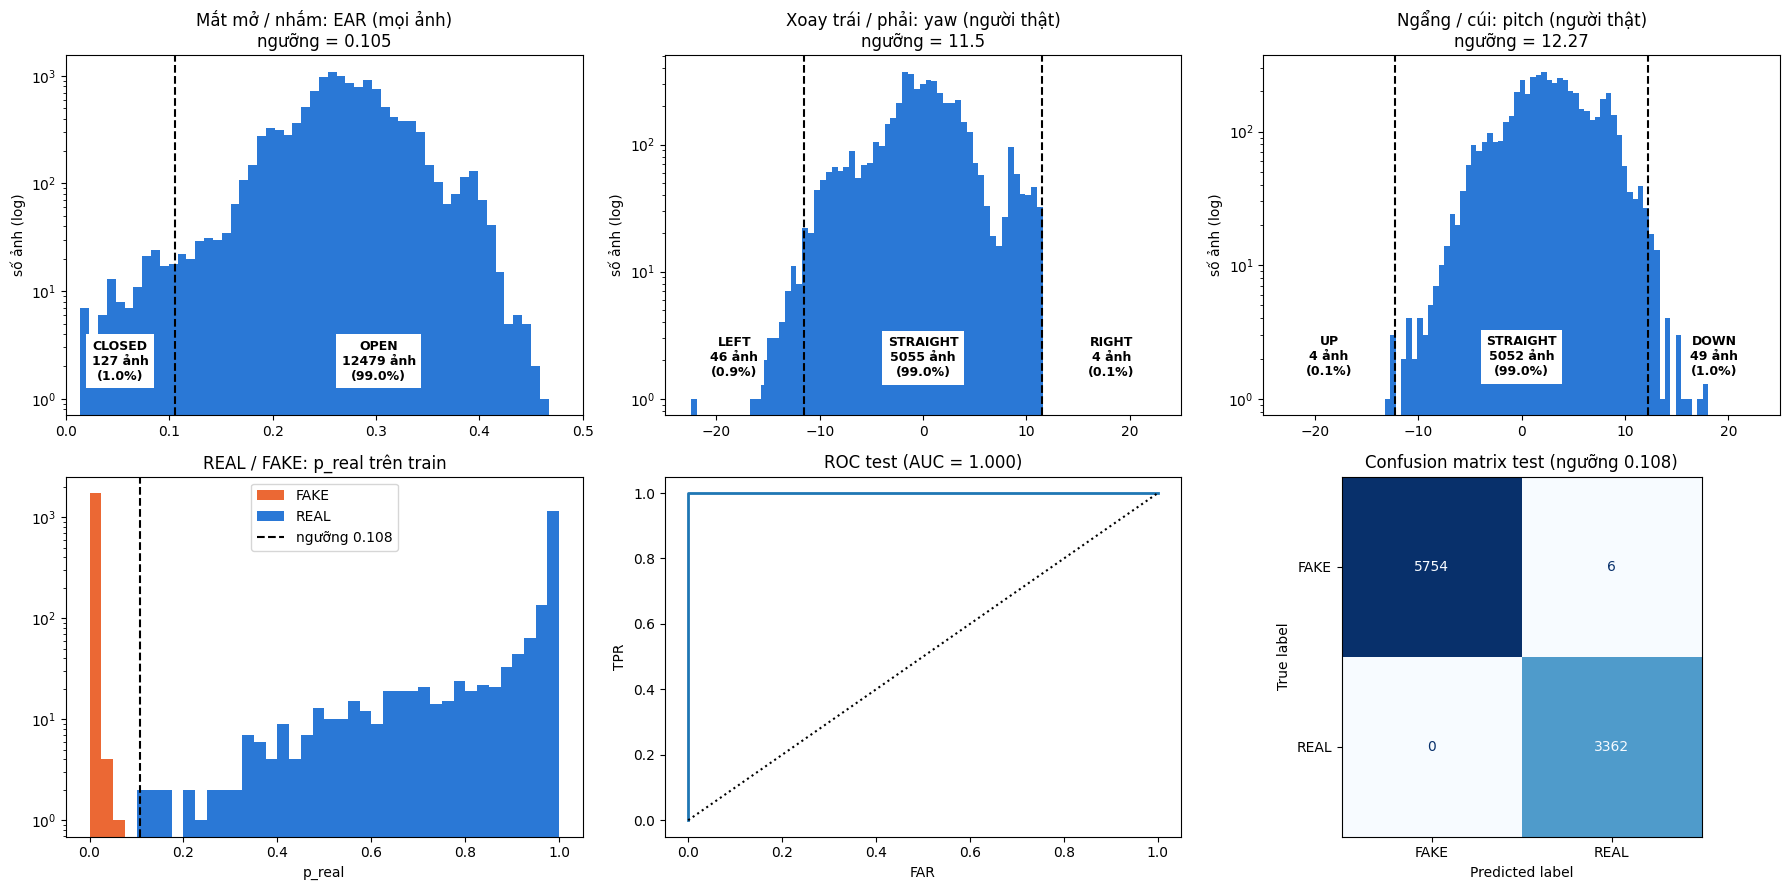

,Nhận diện,Số đo,Ngưỡng,Cách tìm
0,Mắt nhắm (CLOSED),EAR,< 0.105,99% ảnh có EAR lớn hơn
1,Xoay trái / phải,yaw (°),< -11.5 / > 11.5,99% ảnh người thật nhìn thẳng có |yaw| nhỏ hơn
2,Ngẩng / cúi,pitch (°),< -12.27 / > 12.27,99% ảnh người thật nhìn thẳng có |pitch| nhỏ hơn
3,REAL (người thật),p_real,>= 0.108,"ROC trên train, Youden: TPR − FPR lớn nhất"


In [7]:
# ======================= MỤC VẼ BẢNG =======================
def plot_threshold(a, v, t, names, title):
    """Phân bố + vạch ngưỡng + số ảnh mỗi vùng."""
    two = len(names) == 2
    cuts = [t] if two else [-t, t]
    masks = [v < t, v >= t] if two else [v < -t, v.abs() <= t, v > t]
    a.hist(v, 60, color="#2a78d6", log=True)
    a.set_xlim((0, 0.5) if two else (-25, 25))
    for c in cuts: a.axvline(c, color="k", ls="--")
    edges = [a.get_xlim()[0], *cuts, a.get_xlim()[1]]
    for name, m, lo, hi in zip(names, masks, edges, edges[1:]):
        a.text((lo + hi) / 2, 1.5, f"{name}\n{m.sum()} ảnh\n({m.mean():.1%})", ha="center", fontsize=9,
               fontweight="bold", bbox=dict(facecolor="white", edgecolor="none"))
    a.set(title=f"{title}\nngưỡng = {t}", ylabel="số ảnh (log)")

fig, ax = plt.subplots(2, 3, figsize=(18, 9))
plot_threshold(ax[0, 0], df.ear, TH["eye"], ["CLOSED", "OPEN"], "Mắt mở / nhắm: EAR (mọi ảnh)")
plot_threshold(ax[0, 1], real.yaw, TH["yaw"], ["LEFT", "STRAIGHT", "RIGHT"], "Xoay trái / phải: yaw (người thật)")
plot_threshold(ax[0, 2], real.pitch, TH["pitch"], ["UP", "STRAIGHT", "DOWN"], "Ngẩng / cúi: pitch (người thật)")

for lab, color, name in [(0, "#eb6834", "FAKE"), (1, "#2a78d6", "REAL")]:
    ax[1, 0].hist(tr[tr.label == lab].p_real, np.linspace(0, 1, 41), color=color, log=True, label=name)
ax[1, 0].axvline(TH["real"], color="k", ls="--", label=f"ngưỡng {TH['real']}")
ax[1, 0].set(title="REAL / FAKE: p_real trên train", xlabel="p_real"); ax[1, 0].legend()

f_te, t_te, _ = roc_curve(te.label, te.p_real)
ax[1, 1].plot(f_te, t_te, lw=2); ax[1, 1].plot([0, 1], [0, 1], "k:")
ax[1, 1].set(title=f"ROC test (AUC = {roc_auc_score(te.label, te.p_real):.3f})", xlabel="FAR", ylabel="TPR")
ConfusionMatrixDisplay(cm, display_labels=["FAKE", "REAL"]).plot(ax=ax[1, 2], colorbar=False, cmap="Blues")
ax[1, 2].set_title(f"Confusion matrix test (ngưỡng {TH['real']})")
plt.tight_layout(); plt.show()

# Bảng ngưỡng
display(pd.DataFrame([
    ["Mắt nhắm (CLOSED)",      "EAR",     f"< {TH['eye']}",    "99% ảnh có EAR lớn hơn"],
    ["Xoay trái / phải",       "yaw (°)", f"< -{TH['yaw']} / > {TH['yaw']}",     "99% ảnh người thật nhìn thẳng có |yaw| nhỏ hơn"],
    ["Ngẩng / cúi",            "pitch (°)", f"< -{TH['pitch']} / > {TH['pitch']}", "99% ảnh người thật nhìn thẳng có |pitch| nhỏ hơn"],
    ["REAL (người thật)",      "p_real",  f">= {TH['real']}",  "ROC trên train, Youden: TPR − FPR lớn nhất"]],
    columns=["Nhận diện", "Số đo", "Ngưỡng", "Cách tìm"]))